In [1]:
import aiohttp
import asyncio
import pandas as pd
import plotly.graph_objects as go

LEAGUE_ID = 237247   # FPLUzbekistan
UZBEKISTAN = 251     # O'zbekiston

# --- 1. Liga a'zolarini yuklash ---
async def fetch_league_entries(league_id):
    page = 1
    all_results = []
    async with aiohttp.ClientSession() as session:
        while True:
            url = f"https://fantasy.premierleague.com/api/leagues-classic/{league_id}/standings/?page_standings={page}"
            async with session.get(url) as resp:
                data = await resp.json()
                results = data["standings"]["results"]
                if not results:
                    break
                all_results.extend(results)
                if not data["standings"]["has_next"]:
                    break
                page += 1
    return all_results

# --- 2. Overall static ---
async def fetch_overall_data():
    url = "https://fantasy.premierleague.com/api/bootstrap-static/"
    async with aiohttp.ClientSession() as session:
        async with session.get(url) as resp:
            return await resp.json()

# --- 3. Asosiy ish ---
async def main():
    # Ma'lumotlarni olish
    entries = await fetch_league_entries(LEAGUE_ID)      # FPLUzbekistan
    uzb = await fetch_league_entries(UZBEKISTAN)         # O'zbekiston
    overall = await fetch_overall_data()

    kanal_count = len(entries)
    overall_count = overall["total_players"]
    uzbekistan_count = len(uzb)

    print(f"🔹 Yuklangan menejerlar soni: {kanal_count} ta (FPLUzbekistan) | {overall_count} ta (overall) | {uzbekistan_count} ta (O'zbekiston)")

    # DataFrame — kanal
    df = pd.DataFrame([{
        "Ism": e["player_name"],
        "Jamoa": e["entry_name"],
        "Ball": e["event_total"],
        "Umumiy ball": e["total"]
    } for e in entries])

    # DataFrame — O'zbekiston
    df1 = pd.DataFrame([{
        "Ism": e["player_name"],
        "Jamoa": e["entry_name"],
        "Ball": e["event_total"],
        "Umumiy ball": e["total"]
    } for e in uzb])

    # FPLUzbekistan statistikasi
    kanal_avg = df["Ball"].mean()
    kanal_max = df["Ball"].max()

    # O'zbekiston statistikasi
    uzb_avg = df1["Ball"].mean()
    uzb_max = df1["Ball"].max()

    # Hozirgi tur
    current_gw = next(ev for ev in overall["events"] if ev["is_current"])
    gw_name = current_gw["name"]
    overall_avg = current_gw["average_entry_score"]
    overall_highest = current_gw["highest_score"]

    # --- Plotly grafik ---
    metrics = ["O‘rtacha ball", "Eng yuqori ball"]
    kanal_values = [kanal_avg, kanal_max]
    uzb_values = [uzb_avg, uzb_max]
    overall_values = [overall_avg, overall_highest]

    fig = go.Figure()

    # Kanal barlari
    fig.add_trace(go.Bar(
        x=metrics,
        y=kanal_values,
        name=f"FPLUzbekistan ({kanal_count} ta)",
        text=[f"{v:.1f}" for v in kanal_values],
        textposition="outside",
        marker_color="royalblue",
        opacity=0.8
    ))

    # O'zbekiston barlari
    fig.add_trace(go.Bar(
        x=metrics,
        y=uzb_values,
        name=f"O'zbekiston ({uzbekistan_count} ta)",
        text=[f"{v:.1f}" for v in uzb_values],
        textposition="outside",
        marker_color="aquamarine",
        opacity=0.8
    ))

    # Overall barlari
    fig.add_trace(go.Bar(
        x=metrics,
        y=overall_values,
        name=f"Overall ({overall_count:,} ta)",
        text=[str(v) for v in overall_values],
        textposition="outside",
        marker_color="indianred",
        opacity=0.8
    ))

    fig.update_layout(
        title=f"📊 {gw_name} — FPLUzbekistan vs O'zbekiston vs Overall",
        barmode="group",
        yaxis=dict(title="Ball"),
        legend=dict(x=0.5, y=-0.15, orientation="h", xanchor="center"),
        template="plotly_white",
        width=950,
        height=600,
        margin=dict(b=80)
    )

    # Manba annotatsiyasi
    fig.add_annotation(
        text="Manba: t.me/FPLUzbekistan",
        xref="paper", yref="paper",
        x=-0.1, y=-0.2,
        showarrow=False,
        font=dict(size=12, color="black"),
        align="left"
    )

    fig.show()

# Run
await main()


🔹 Yuklangan menejerlar soni: 935 ta (FPLUzbekistan) | 13052079 ta (overall) | 9949 ta (O'zbekiston)


✅ FPLUzbekistan — jami 911 ta a’zo yuklandi


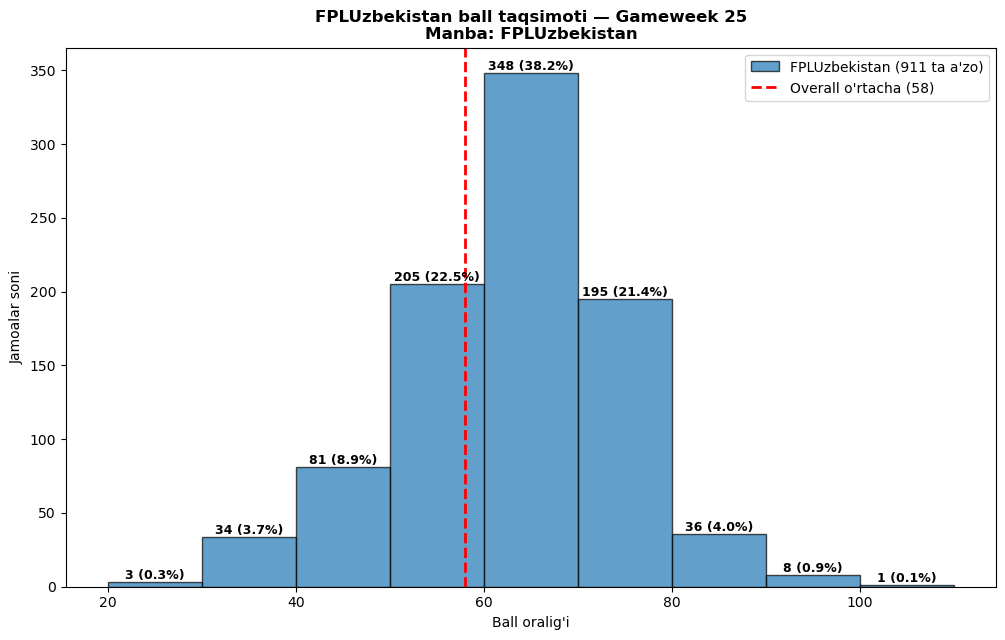

In [1]:
import aiohttp
import asyncio
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Liga a'zolarini olish ---
async def fetch_league_entries(league_id, session):
    page = 1
    entries = []
    league_name = ""
    while True:
        url = f"https://fantasy.premierleague.com/api/leagues-classic/{league_id}/standings/?page_standings={page}"
        async with session.get(url) as resp:
            if resp.status != 200:
                print(f"⚠️ Xatolik: {resp.status}")
                break
            data = await resp.json()
            if page == 1:
                league_name = data["league"]["name"]
            new_entries = data["standings"]["results"]
            if not new_entries:
                break
            entries.extend(new_entries)
            page += 1
    return entries, league_name

# --- 2. Overall statistikani olish ---
async def fetch_overall_data(session):
    url = "https://fantasy.premierleague.com/api/bootstrap-static/"
    async with session.get(url) as resp:
        if resp.status != 200:
            print("⚠️ Overall yuklanmadi")
            return None
        return await resp.json()

# --- 3. Tahlil va chizish ---
def analyze_distribution(df, overall_data, league_name):
    # Hozirgi turni topish
    current_gw = next(gw for gw in overall_data["events"] if gw["is_current"])
    gw_id = current_gw["id"]
    gw_name = current_gw["name"]
    overall_avg = current_gw["average_entry_score"]

    kanal_scores = df["Ball"]

    plt.figure(figsize=(12,7))
    counts, bins, patches = plt.hist(
        kanal_scores,
        bins=range(int(min(kanal_scores)//10*10), int(max(kanal_scores)//10*10 + 20), 10),
        alpha=0.7,
        label=f"{league_name} ({len(df)} ta a'zo)",
        edgecolor="black"
    )

    # Har bir ustun tepasiga son va foiz
    total = len(df)
    for count, x in zip(counts, bins):
        if count > 0:
            percent = (count / total) * 100
            plt.text(x + 5, count, f"{int(count)} ({percent:.1f}%)",
                     ha="center", va="bottom", fontsize=9, fontweight="bold")

    # Overall o'rtacha chizig'i
    plt.axvline(overall_avg, color="red", linestyle="dashed", linewidth=2,
                label=f"Overall o'rtacha ({overall_avg})")

    plt.xlabel("Ball oralig'i")
    plt.ylabel("Jamoalar soni")
    plt.title(f"{league_name} ball taqsimoti — {gw_name}\nManba: FPLUzbekistan", weight="bold")
    plt.legend()
    plt.show()

# --- 4. Asosiy funksiya ---
async def main():
    league_id = 237247  # FPLUzbekistan ligasi
    async with aiohttp.ClientSession() as session:
        entries, league_name = await fetch_league_entries(league_id, session)
        overall_data = await fetch_overall_data(session)

    # DataFrame tayyorlash
    df = pd.DataFrame([{
        "Ism": e.get("player_name", "Noma'lum"),
        "Jamoa": e.get("entry_name", "Noma'lum"),
        "Ball": e.get("event_total", 0),
        "Umumiy ball": e.get("total", 0)
    } for e in entries])

    print(f"✅ {league_name} — jami {len(df)} ta a’zo yuklandi")
    analyze_distribution(df, overall_data, league_name)

# --- Run ---
await main()


In [5]:
import aiohttp
import asyncio
import pandas as pd
import plotly.graph_objects as go
from collections import Counter, defaultdict

# --- 1. Liga a'zolarini olish ---
async def fetch_league_entries(league_id, session):
    page, entries, league_name = 1, [], ""
    while True:
        url = f"https://fantasy.premierleague.com/api/leagues-classic/{league_id}/standings/?page_standings={page}"
        async with session.get(url) as resp:
            if resp.status != 200:
                break
            data = await resp.json()
            if page == 1:
                league_name = data["league"]["name"]
            new_entries = data["standings"]["results"]
            if not new_entries:
                break
            entries.extend(new_entries)
            page += 1
    return entries, league_name

# --- 2. Overall ma'lumot ---
async def fetch_overall_data(session):
    url = "https://fantasy.premierleague.com/api/bootstrap-static/"
    async with session.get(url) as resp:
        if resp.status != 200:
            return None
        return await resp.json()

# --- 3. Picks ---
async def fetch_team_picks(entry_id, gw, session):
    url = f"https://fantasy.premierleague.com/api/entry/{entry_id}/event/{gw}/picks/"
    async with session.get(url) as resp:
        if resp.status != 200:
            return None
        return await resp.json()

# --- 4. Asosiy ---
async def main():
    league_id = 237247   # FPLUzbekistan
    async with aiohttp.ClientSession() as session:
        entries, league_name = await fetch_league_entries(league_id, session)
        overall_data = await fetch_overall_data(session)

        # Hozirgi turni topish
        current_gw = next(gw for gw in overall_data["events"] if gw["is_current"])
        gw = current_gw["id"]
        gw_name = current_gw["name"]

        player_map = {p["id"]: p["web_name"] for p in overall_data["elements"]}

        captain_counter = Counter()
        captain_team_points = defaultdict(list)

        for i, e in enumerate(entries, start=1):
            team_id = e["entry"]
            picks = await fetch_team_picks(team_id, gw, session)
            if not picks:
                continue
            team_points = picks.get("entry_history", {}).get("points", 0)
            for p in picks["picks"]:
                if p["is_captain"]:
                    pid = p["element"]
                    captain_counter[pid] += 1
                    captain_team_points[pid].append(team_points)
            if i % 100 == 0:
                print(f"⏳ {i} jamoa yuklandi...")

        # DF
        data = []
        for pid, count in captain_counter.items():
            avg_points = sum(captain_team_points[pid]) / len(captain_team_points[pid])
            data.append({
                "Kapitan": player_map.get(pid, f"ID {pid}"),
                "Tanlanganlar soni": count,
                "O'rtacha jamoa balli": round(avg_points, 2)
            })

        df = pd.DataFrame(data).sort_values("Tanlanganlar soni", ascending=False)
        df_top10 = df.head(10)

        print(f"✅ {league_name} ({len(entries)} a'zo) — {gw_name} TOP-10 Sardor statistikasi")
        print(df_top10)

        # --- Plotly grafik ---
        fig = go.Figure()

        # Bar (o'rtacha ball)
        fig.add_trace(go.Bar(
            x=df_top10["Kapitan"],
            y=df_top10["O'rtacha jamoa balli"],
            name="O'rtacha jamoa balli",
            marker_color="skyblue",
            yaxis="y1",
            text=df_top10["O'rtacha jamoa balli"],
            textposition="outside"
        ))

        # Line (tanlov soni)
        fig.add_trace(go.Scatter(
            x=df_top10["Kapitan"],
            y=df_top10["Tanlanganlar soni"],
            name="Tanlanganlar soni",
            mode="lines+markers+text",
            text=df_top10["Tanlanganlar soni"],
            textposition="top center",
            line=dict(color="red", width=2),
            yaxis="y2"
        ))

        # Layout
        fig.update_layout(
            title=f"{league_name} — {gw_name} TOP-10 Sardor tanlovlari "
                  f"({len(entries)} a'zo) \nManba: t.me/FPLUzbekistan",
            xaxis=dict(title="Sardor o'yinchi"),
            yaxis=dict(title="O'rtacha jamoa balli", side="left"),
            yaxis2=dict(title="Tanlangan menejerlar soni", side="right", overlaying="y"),
            legend=dict(x=0.5, y=1.1, orientation="h"),
            bargap=0.4,
            template="plotly_white",
            width=1000,
            height=600
        )

        fig.show()

# Run
await main()

⏳ 100 jamoa yuklandi...
⏳ 200 jamoa yuklandi...
⏳ 300 jamoa yuklandi...
⏳ 400 jamoa yuklandi...
⏳ 500 jamoa yuklandi...
⏳ 600 jamoa yuklandi...
⏳ 700 jamoa yuklandi...
⏳ 800 jamoa yuklandi...
✅ FPLUzbekistan (879 a'zo) — Gameweek 19 TOP-10 Sardor statistikasi
        Kapitan  Tanlanganlar soni  O'rtacha jamoa balli
0       Haaland                488                 42.09
1       Ekitiké                 89                 41.91
2         Cunha                 58                 43.83
9    João Pedro                 22                 41.41
12        Foden                 20                 45.55
17  B.Fernandes                 18                 39.67
32      M.Salah                 18                 35.00
3        Palmer                 15                 47.20
11    Woltemade                 13                 40.54
26     Gyökeres                 13                 37.62


In [15]:
import plotly.graph_objects as go

# --- Misol uchun sun’iy ma’lumot ---
metrics = ["xG", "xA", "Shots", "Shots on Target", "Chances Created",
           "Crosses", "Big Chances", "Touches (Box)", "Final 3rd Passes", "Throughballs"]

sarr_stats = [0.45, 0.18, 4, 2, 1, 1, 1, 8, 3, 0]
kudus_stats = [0.35, 0.25, 3, 1, 3, 4, 1, 5, 2, 1]

# --- Radar chizish ---
fig = go.Figure()

fig.add_trace(go.Scatterpolar(
    r=sarr_stats,
    theta=metrics,
    fill='toself',
    name='Saka',
    line_color='deepskyblue'
))

fig.add_trace(go.Scatterpolar(
    r=kudus_stats,
    theta=metrics,
    fill='toself',
    name='Haaland',
    line_color='crimson'
))

fig.update_layout(
    polar=dict(
        radialaxis=dict(visible=True, range=[0, max(sarr_stats + kudus_stats) + 1])
    ),
    title="Sarr vs Kudus — Statistika taqqoslash",
    showlegend=True,
    template="plotly_white",
    width=700,
    height=600
)

fig.show()


Saqlangan fayl: top20_clean.png


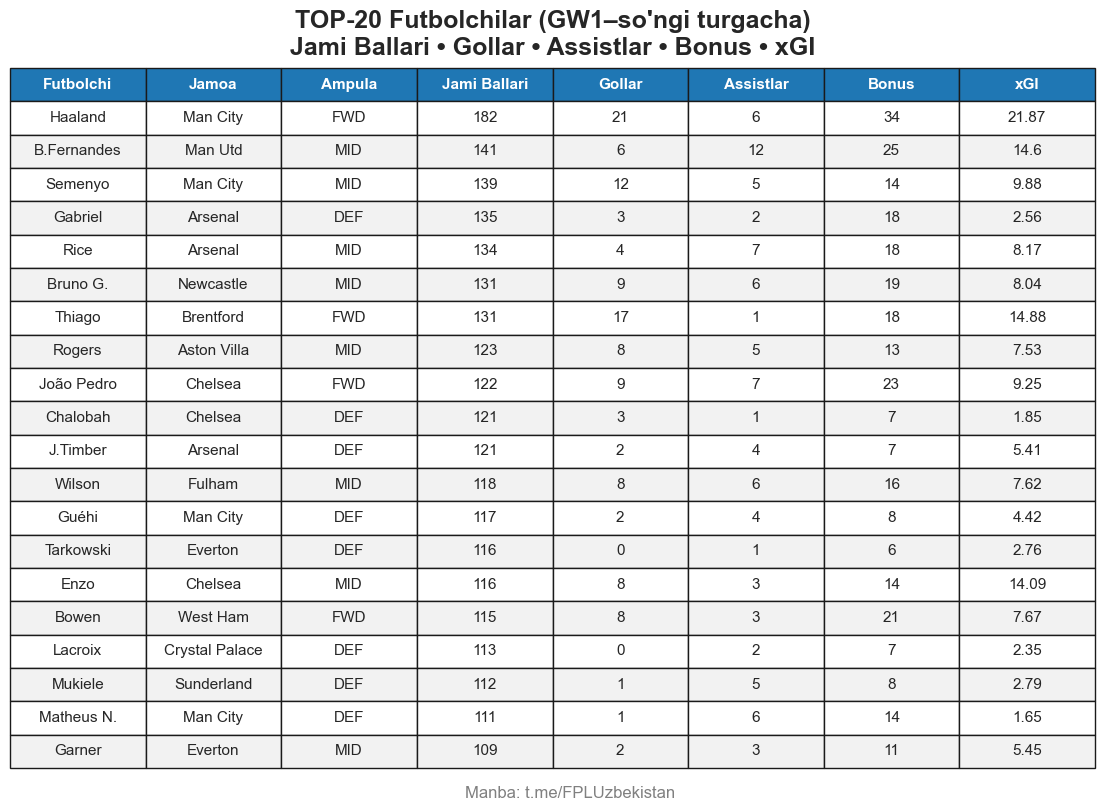

In [3]:
import aiohttp
import asyncio
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# FPL ma'lumotlarini olish
async def fetch_static():
    url = "https://fantasy.premierleague.com/api/bootstrap-static/"
    async with aiohttp.ClientSession() as session:
        async with session.get(url) as resp:
            return await resp.json()

async def main():
    static = await fetch_static()
    players = static["elements"]
    teams = {t["id"]: t["name"] for t in static["teams"]}
    position = {s["id"]: s["plural_name_short"] for s in static["element_types"]}

    data = []
    for p in players:
        data.append({
            "Futbolchi": p["web_name"],
            "Jamoa": teams[p["team"]],
            "Ampula": position[p["element_type"]],
            "Jami Ballari": p["total_points"],
            "Gollar": p["goals_scored"],
            "Assistlar": p["assists"],
            "Bonus": p["bonus"],
            "xGI": round(float(p.get("expected_goal_involvements", 0)), 2)
        })

    df = pd.DataFrame(data)
    df = df.sort_values("Jami Ballari", ascending=False).head(20)

    # --- Jadval yaratish (seaborn heatmap emas, style-only plot) ---
    plt.figure(figsize=(14, 8))

    plt.title(
        "TOP-20 Futbolchilar (GW1–so'ngi turgacha)\nJami Ballari • Gollar • Assistlar • Bonus • xGI",
        fontsize=18, fontweight="bold", pad=40
    )

    # Jadvalni chiroyli render qilish
    ax = plt.gca()
    ax.axis("off")

    table = plt.table(
        cellText=df.values,
        colLabels=df.columns,
        cellLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 2)

    # Header style
    for key, cell in table.get_celld().items():
        r, c = key
        if r == 0:
            cell.set_text_props(weight="bold", color="white")
            cell.set_facecolor("#1f77b4")
        elif r % 2 == 0:
            cell.set_facecolor("#f2f2f2")
        else:
            cell.set_facecolor("#ffffff")

    # --- Manba ---
    plt.figtext(
        0.60, 0.02,
        "Manba: t.me/FPLUzbekistan",
        ha="right",
        fontsize=12,
        color="gray"
    )

    plt.savefig("top20_clean.png", dpi=300, bbox_inches="tight")
    print("Saqlangan fayl: top20_clean.png")

await main()


In [4]:
import aiohttp
import asyncio
import pandas as pd

LEAGUE_ID = 237247
OUTPUT_FILE = "fpluzbekistan_league_members.csv"

# -------------------------
# Liga a'zolarini yuklash
# -------------------------
async def fetch_league_members(league_id):
    page = 1
    members = []

    async with aiohttp.ClientSession() as session:
        while True:
            url = f"https://fantasy.premierleague.com/api/leagues-classic/{league_id}/standings/?page_standings={page}"
            async with session.get(url) as resp:
                if resp.status != 200:
                    print("❌ Xatolik:", resp.status)
                    break

                data = await resp.json()
                results = data["standings"]["results"]

                if not results:
                    break

                for r in results:
                    members.append({
                        "entry_id": r["entry"],
                        "Menejer ismi": r["player_name"],
                        "Jamoa nomi": r["entry_name"],
                        "Hozirgi tur balli": r["event_total"],
                        "Umumiy ball": r["total"],
                        "Liga reytingi": r["rank"]
                    })

                if not data["standings"]["has_next"]:
                    break

                page += 1

    return members

# -------------------------
# Asosiy ish
# -------------------------
async def main():
    print("⏳ Liga a'zolari yuklanmoqda...")
    members = await fetch_league_members(LEAGUE_ID)

    df = pd.DataFrame(members)
    df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")

    print(f"✅ Jami {len(df)} ta menejer yuklandi")
    print(f"📁 CSV fayl saqlandi: {OUTPUT_FILE}")

# RUN
await main()


⏳ Liga a'zolari yuklanmoqda...
✅ Jami 911 ta menejer yuklandi
📁 CSV fayl saqlandi: fpluzbekistan_league_members.csv


In [2]:
import aiohttp
import asyncio

LEAGUE_ID = 237247

# --- Liga a'zolarini olish ---
async def fetch_league_entries(league_id):
    page = 1
    all_results = []

    async with aiohttp.ClientSession() as session:
        while True:
            url = f"https://fantasy.premierleague.com/api/leagues-classic/{league_id}/standings/?page_standings={page}"
            async with session.get(url) as resp:
                data = await resp.json()
                results = data["standings"]["results"]

                if not results:
                    break

                all_results.extend(results)

                if not data["standings"]["has_next"]:
                    break

                page += 1

    return all_results

# --- Asosiy funksiya ---
async def main():
    print("⏳ Liga a'zolari yuklanmoqda...")
    entries = await fetch_league_entries(LEAGUE_ID)

    if not entries:
        print("❌ Ma'lumot topilmadi")
        return

    # Oxirgi tur bo‘yicha eng katta ball
    max_score = max(e["event_total"] for e in entries)

    best_managers = [e for e in entries if e["event_total"] == max_score]

    print("\n🔥 OXIRGI TUR ENG YUQORI BALL:")
    print(f"🏆 Eng katta ball: {max_score}\n")

    for i, m in enumerate(best_managers, 1):
        print(f"{i}. 👤 Menejer: {m['player_name']}")
        print(f"   🆔 User ID (entry): {m['entry']}")
        print(f"   🏷 Jamoa: {m['entry_name']}")
        print("")

# RUN
await main()


⏳ Liga a'zolari yuklanmoqda...

🔥 OXIRGI TUR ENG YUQORI BALL:
🏆 Eng katta ball: 94

1. 👤 Menejer: Baxtiyor Egamov
   🆔 User ID (entry): 4488126
   🏷 Jamoa: Meloman_R90



C:\Users\user\AppData\Local\Temp\ipykernel_26268\3238544319.py:116: UserWarning:

Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.

C:\Users\user\AppData\Local\Temp\ipykernel_26268\3238544319.py:116: UserWarning:

Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.

C:\Users\user\AppData\Local\Temp\ipykernel_26268\3238544319.py:116: UserWarning:

Glyph 127991 (\N{LABEL}) missing from font(s) DejaVu Sans.

C:\Users\user\AppData\Local\Temp\ipykernel_26268\3238544319.py:116: UserWarning:

Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.

C:\Users\user\AppData\Local\Temp\ipykernel_26268\3238544319.py:116: UserWarning:

Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.

c:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.

c:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128100 (\N{BUST IN SILHOUETTE}) 

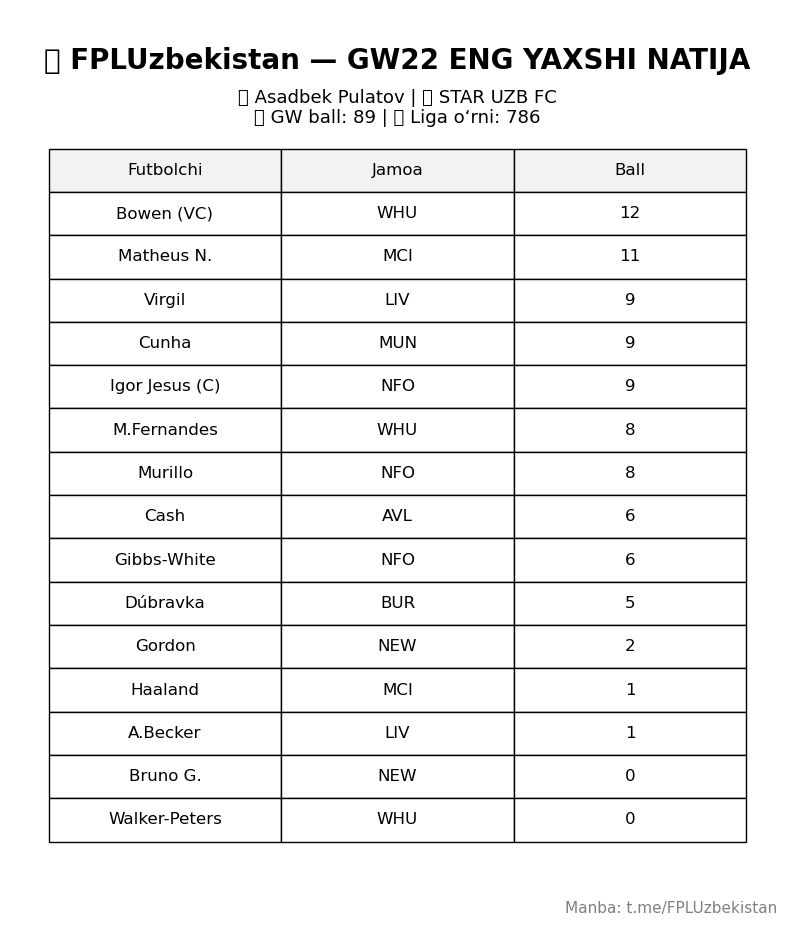

✅ Tayyor post rasmi saqlandi: FPLUzbekistan_GW22_BestManager.png


In [4]:
import aiohttp
import asyncio
import pandas as pd
import matplotlib.pyplot as plt

LEAGUE_ID = 237247


# ---------- API FUNKSIYALAR ----------
async def fetch_json(session, url):
    async with session.get(url) as resp:
        return await resp.json()


async def fetch_league_entries(session):
    page = 1
    all_results = []

    while True:
        url = f"https://fantasy.premierleague.com/api/leagues-classic/{LEAGUE_ID}/standings/?page_standings={page}"
        data = await fetch_json(session, url)

        results = data["standings"]["results"]
        if not results:
            break

        all_results.extend(results)

        if not data["standings"]["has_next"]:
            break

        page += 1

    return all_results


async def fetch_team_picks(session, entry_id, gw):
    url = f"https://fantasy.premierleague.com/api/entry/{entry_id}/event/{gw}/picks/"
    return await fetch_json(session, url)


# ---------- ASOSIY ISH ----------
async def main():
    async with aiohttp.ClientSession() as session:
        overall = await fetch_json(session, "https://fantasy.premierleague.com/api/bootstrap-static/")
        events = overall["events"]
        players = overall["elements"]
        teams = overall["teams"]

        current_gw = max([e["id"] for e in events if e["finished"]])

        entries = await fetch_league_entries(session)

        max_score = max(e["event_total"] for e in entries)
        best = [e for e in entries if e["event_total"] == max_score][0]

        entry_id = best["entry"]
        manager_name = best["player_name"]
        team_name = best["entry_name"]
        gw_rank = best["rank"]
        gw_points = best["event_total"]

        picks_data = await fetch_team_picks(session, entry_id, current_gw)

        picks = picks_data["picks"]
        stats = picks_data["entry_history"]

        player_map = {p["id"]: p for p in players}
        team_map = {t["id"]: t["short_name"] for t in teams}

        squad = []
        for p in picks:
            pl = player_map[p["element"]]
            name = pl["web_name"]
            team = team_map[pl["team"]]
            points = pl["event_points"]

            role = ""
            if p["is_captain"]:
                role = " (C)"
            elif p["is_vice_captain"]:
                role = " (VC)"

            squad.append([f"{name}{role}", team, points])

        df = pd.DataFrame(squad, columns=["Futbolchi", "Jamoa", "Ball"])
        df = df.sort_values("Ball", ascending=False)

    # ---------- VIZUAL POST ----------
    plt.figure(figsize=(10, 12))
    plt.axis("off")

    title = f"🔥 FPLUzbekistan — GW{current_gw} ENG YAXSHI NATIJA\n"
    subtitle = f"👤 {manager_name} | 🏷 {team_name}\n🏆 GW ball: {gw_points} | 📊 Liga o‘rni: {gw_rank}"

    plt.text(0.5, 0.96, title, ha="center", va="top", fontsize=20, weight="bold")
    plt.text(0.5, 0.915, subtitle, ha="center", va="top", fontsize=13)

    table = plt.table(
        cellText=df.values,
        colLabels=df.columns,
        colColours=["#f2f2f2"]*3,
        cellLoc="center",
        loc="center",
        bbox=[0.05, 0.1, 0.9, 0.75]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.6)

    plt.text(0.99, 0.02, "Manba: t.me/FPLUzbekistan",
             ha="right", va="bottom", fontsize=11, color="gray")

    output_file = f"FPLUzbekistan_GW{current_gw}_BestManager.png"
    plt.savefig(output_file, dpi=200, bbox_inches="tight")
    plt.show()

    print("✅ Tayyor post rasmi saqlandi:", output_file)


# RUN
await main()
